# Disaster Tweets — DistilBERT fine-tuning dengan PyTorch murni

Notebook ini adalah versi **PyTorch + Hugging Face Transformers** dari starter notebook KerasNLP. Tidak ada lagi `keras`, `keras_nlp`, maupun TensorFlow.

In this competition, the challenge is to build a machine learning model that predicts which Tweets are about real disasters and which one's aren't.
A dataset of 10,000 tweets that were hand classified is available.

__This notebook fine-tunes the [DistilBERT](https://arxiv.org/abs/1910.01108) pretrained model with PyTorch.__

**BERT** stands for **Bidirectional Encoder Representations from Transformers**. BERT and other Transformer encoder architectures have been wildly successful on a variety of tasks in NLP (natural language processing). They compute vector-space representations of natural language that are suitable for use in deep learning models.

The BERT family of models uses the **Transformer encoder architecture** to process each token of input text in the full context of all tokens before and after, hence the name: Bidirectional Encoder Representations from Transformers.

BERT models are usually pre-trained on a large corpus of text, then fine-tuned for specific tasks.

**DistilBERT model** is a distilled form of the **BERT** model. The size of a BERT model was reduced by 40% via knowledge distillation during the pre-training phase while retaining 97% of its language understanding abilities and being 60% faster.

![BERT Architecture](https://www.cse.chalmers.se/~richajo/nlp2019/l5/bert_class.png)

In this notebook, you will:

- Load the Disaster Tweets
- Explore the dataset
- Preprocess the data (tokenizer + `DataLoader`)
- Load a DistilBERT model (Hugging Face / PyTorch)
- Train your own model with a manual PyTorch training loop
- Generate the submission file

In [2]:
!pip install -q torch transformers scikit-learn pandas matplotlib tqdm

import os
import copy
import random
import contextlib

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import transformers
print("Torch version:", torch.__version__)
print("Transformers version:", transformers.__version__)

Torch version: 2.11.0+cu128
Transformers version: 5.14.1


In [3]:
# ===== Konfigurasi =====
SEED = 42

# Folder model lokal (format Hugging Face: config.json + model.safetensors / pytorch_model.bin + vocab.txt)
MODEL_DIR = "../pretrained/distilbert_en"
# Dipakai hanya jika MODEL_DIR tidak valid (butuh internet)
FALLBACK_MODEL = "distilbert-base-uncased"

MAX_LEN = 160
BATCH_SIZE = 32
EPOCHS = 2
LR = 3e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
VAL_SPLIT = 0.2


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# Mixed precision (fp16) hanya dipakai di GPU NVIDIA
use_amp = device.type == "cuda"
print("Device:", device, "| AMP:", use_amp)

Device: cuda | AMP: True


# Load the Disaster Tweets
Let's have a look at the train and test dataset.

They contain:
- id
- keyword: A keyword from that tweet (although this may be blank!)
- location: The location the tweet was sent from (may also be blank)
- text: The text of a tweet
- target: 1 if the tweet is a real disaster or 0 if not

In [4]:
KAGGLE_DIR = "/kaggle/input/nlp-getting-started"

def find_file(filename):
    """Cari file di folder kerja, lalu di folder input Kaggle."""
    for folder in [".", KAGGLE_DIR]:
        path = os.path.join(folder, filename)
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"{filename} tidak ditemukan di '.' maupun '{KAGGLE_DIR}'")

df_train = pd.read_csv(find_file("train.csv"))
df_test = pd.read_csv(find_file("test.csv"))

print('Training Set Shape = {}'.format(df_train.shape))
print('Training Set Memory Usage = {:.2f} MB'.format(df_train.memory_usage().sum() / 1024**2))
print('Test Set Shape = {}'.format(df_test.shape))
print('Test Set Memory Usage = {:.2f} MB'.format(df_test.memory_usage().sum() / 1024**2))

Training Set Shape = (7613, 5)
Training Set Memory Usage = 0.29 MB
Test Set Shape = (3263, 4)
Test Set Memory Usage = 0.10 MB


In [5]:
df_train.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [6]:
df_test.head()

,id,keyword,location,text
0,0,NaN,NaN,Just happened a terrible car crash
1,2,NaN,NaN,"Heard about #earthquake is different cities, s..."
2,3,NaN,NaN,"there is a forest fire at spot pond, geese are..."
3,9,NaN,NaN,Apocalypse lighting. #Spokane #wildfires
4,11,NaN,NaN,Typhoon Soudelor kills 28 in China and Taiwan


# Explore the dataset

In [7]:
df_train["length"] = df_train["text"].apply(lambda x : len(x))
df_test["length"] = df_test["text"].apply(lambda x : len(x))

print("Train Length Stat")
print(df_train["length"].describe())
print()

print("Test Length Stat")
print(df_test["length"].describe())

Train Length Stat
count    7613.000000
mean      101.037436
std        33.781325
min         7.000000
25%        78.000000
50%       107.000000
75%       133.000000
max       157.000000
Name: length, dtype: float64

Test Length Stat
count    3263.000000
mean      102.108183
std        33.972158
min         5.000000
25%        78.000000
50%       109.000000
75%       134.000000
max       151.000000
Name: length, dtype: float64


If you want to know more information about the data, you can grab useful information [here](https://www.kaggle.com/code/gunesevitan/nlp-with-disaster-tweets-eda-cleaning-and-bert)

Note that all the tweets are in english.

# Preprocess the data

In [8]:
def to_clean_list(series):
    """Isi NaN dengan string kosong, pastikan semuanya str, lalu jadikan list."""
    return series.fillna("").astype(str).tolist()

X = to_clean_list(df_train["text"])
y = df_train["target"].to_numpy()

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=VAL_SPLIT, random_state=SEED
)
X_test = to_clean_list(df_test["text"])

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print(X_train[:3])

Train: 6090 | Val: 1523 | Test: 3263
['Courageous and honest analysis of need to use Atomic Bomb in 1945. #Hiroshima70 Japanese military refused surrender. https://t.co/VhmtyTptGR', '@ZachZaidman @670TheScore wld b a shame if that golf cart became engulfed in flames. #boycottBears', "Tell @BarackObama to rescind medals of 'honor' given to US soldiers at the Massacre of Wounded Knee. SIGN NOW &amp; RT! https://t.co/u4r8dRiuAc"]


# Load a DistilBERT model (PyTorch)

Di PyTorch, tokenisasi dilakukan oleh `AutoTokenizer` dan model klasifikasi oleh `AutoModelForSequenceClassification` (DistilBERT + classification head dengan 2 kelas). Peringatan *"Some weights ... newly initialized"* saat memuat model itu normal: head klasifikasi memang baru dan akan dilatih.

DistilBERT has 40% fewer parameters than bert-base-uncased, runs 60% faster while preserving over 95% of BERT's performance on GLUE. Specifically, it doesn't have token-type embeddings, pooler and retains only half of the layers from Google's BERT.

In [9]:
def is_hf_folder(folder):
    """True jika folder berisi model format Hugging Face (bukan preset Keras)."""
    if not os.path.isdir(folder):
        return False
    has_config = os.path.exists(os.path.join(folder, "config.json"))
    has_weights = any(
        os.path.exists(os.path.join(folder, f))
        for f in ["model.safetensors", "pytorch_model.bin"]
    )
    return has_config and has_weights

if is_hf_folder(MODEL_DIR):
    model_source = MODEL_DIR
    print(f"Memuat model dari folder lokal: {MODEL_DIR}")
else:
    model_source = FALLBACK_MODEL
    print(f"'{MODEL_DIR}' bukan folder model Hugging Face yang valid "
          f"(butuh config.json + model.safetensors/pytorch_model.bin).")
    if os.path.isdir(MODEL_DIR):
        print("Isi folder:", os.listdir(MODEL_DIR))
    print(f"Fallback: mengunduh '{FALLBACK_MODEL}' dari Hugging Face Hub (butuh internet).")

tokenizer = AutoTokenizer.from_pretrained(model_source)
model = AutoModelForSequenceClassification.from_pretrained(model_source, num_labels=2)
model.to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"\nModel siap. Jumlah parameter: {n_params/1e6:.1f} M")

Memuat model dari folder lokal: ../pretrained/distilbert_en


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 3092.67it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: ../pretrained/distilbert_en
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Model siap. Jumlah parameter: 67.0 M


# Build the DataLoaders

Tokenisasi dilakukan per-batch di dalam `collate_fn` dengan **dynamic padding** (batch hanya dipad sampai panjang teks terpanjang di batch itu, maksimal `MAX_LEN`), sehingga lebih cepat daripada padding semua teks ke 160 token.

In [10]:
class TweetDataset(Dataset):
    def __init__(self, texts, labels=None):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        item = {"text": self.texts[idx]}
        if self.labels is not None:
            item["label"] = int(self.labels[idx])
        return item


def collate_fn(batch):
    enc = tokenizer(
        [b["text"] for b in batch],
        padding=True,
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt",
    )
    if "label" in batch[0]:
        enc["labels"] = torch.tensor([b["label"] for b in batch], dtype=torch.long)
    return enc


def make_loader(texts, labels=None, shuffle=False, batch_size=BATCH_SIZE):
    return DataLoader(
        TweetDataset(texts, labels),
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=collate_fn,
    )


train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val, shuffle=False, batch_size=BATCH_SIZE * 2)

# Cek satu batch
sample = next(iter(train_loader))
print({k: tuple(v.shape) for k, v in sample.items()})

{'input_ids': (32, 54), 'token_type_ids': (32, 54), 'attention_mask': (32, 54), 'labels': (32,)}


# Train your own model, fine-tuning BERT

In [11]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(WARMUP_RATIO * total_steps),
    num_training_steps=total_steps,
)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)


def autocast_ctx():
    if use_amp:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return contextlib.nullcontext()


def to_device(batch):
    return {k: v.to(device) for k, v in batch.items()}


def train_one_epoch(epoch):
    model.train()
    running_loss, correct, seen = 0.0, 0, 0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [train]")
    for batch in pbar:
        batch = to_device(batch)
        optimizer.zero_grad(set_to_none=True)

        with autocast_ctx():
            out = model(**batch)          # out.loss dihitung otomatis karena ada 'labels'

        scaler.scale(out.loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        bs = batch["labels"].size(0)
        running_loss += out.loss.item() * bs
        correct += (out.logits.argmax(dim=-1) == batch["labels"]).sum().item()
        seen += bs
        pbar.set_postfix(loss=running_loss / seen, acc=correct / seen)
    return running_loss / seen, correct / seen


@torch.no_grad()
def evaluate(loader):
    model.eval()
    running_loss, seen = 0.0, 0
    all_preds, all_labels = [], []
    for batch in tqdm(loader, desc="Evaluate", leave=False):
        batch = to_device(batch)
        with autocast_ctx():
            out = model(**batch)
        bs = batch["labels"].size(0)
        running_loss += out.loss.item() * bs
        seen += bs
        all_preds.append(out.logits.argmax(dim=-1).cpu())
        all_labels.append(batch["labels"].cpu())
    preds = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()
    return running_loss / seen, (preds == labels).mean(), f1_score(labels, preds)

In [12]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
best_f1, best_state = -1.0, None

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(epoch)
    val_loss, val_acc, val_f1 = evaluate(val_loader)

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    print(f"Epoch {epoch}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f} F1 {val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})

# Kembalikan bobot terbaik (berdasarkan F1 validasi)
model.load_state_dict(best_state)
model.to(device)
print(f"\nBobot terbaik dimuat (val F1 = {best_f1:.4f})")

Epoch 1/2 [train]: 100%|██████████| 191/191 [00:27<00:00,  6.91it/s, acc=0.79, loss=0.464] 


Epoch 1/2 | train loss 0.4641 acc 0.7905 | val loss 0.4023 acc 0.8267 F1 0.7994


Epoch 2/2 [train]: 100%|██████████| 191/191 [00:26<00:00,  7.12it/s, acc=0.873, loss=0.322]


Epoch 2/2 | train loss 0.3219 acc 0.8729 | val loss 0.3866 acc 0.8450 F1 0.8100

Bobot terbaik dimuat (val F1 = 0.8100)


In [13]:
@torch.no_grad()
def predict_logits(texts):
    """Mengembalikan logits (N, 2) sebagai numpy array."""
    model.eval()
    loader = make_loader(texts, shuffle=False, batch_size=BATCH_SIZE * 2)
    outputs = []
    for batch in tqdm(loader, desc="Predict", leave=False):
        batch = to_device(batch)
        with autocast_ctx():
            logits = model(**batch).logits
        outputs.append(logits.float().cpu())
    return torch.cat(outputs).numpy()


def displayConfusionMatrix(y_true, y_pred, dataset):
    y_hat = np.argmax(y_pred, axis=1)
    disp = ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_hat,
        display_labels=["Not Disaster", "Disaster"],
        cmap=plt.cm.Blues
    )
    f1 = f1_score(y_true, y_hat)
    disp.ax_.set_title("Confusion Matrix on " + dataset + " Dataset -- F1 Score: " + str(round(f1, 2)))

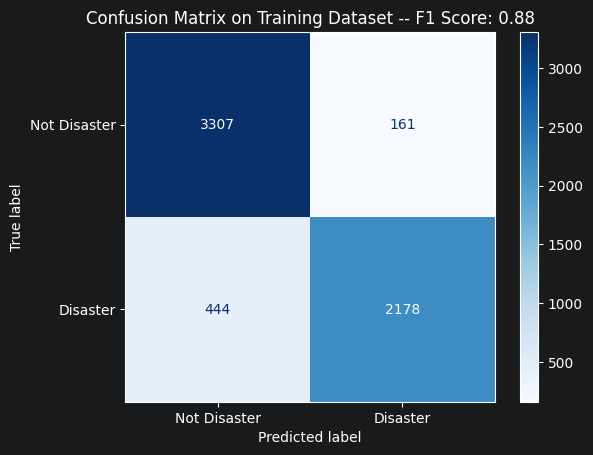

In [14]:
y_pred_train = predict_logits(X_train)
displayConfusionMatrix(y_train, y_pred_train, "Training")

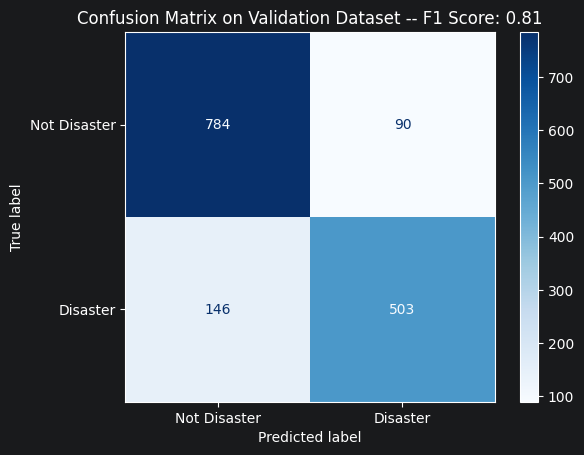

In [15]:
y_pred_val = predict_logits(X_val)
displayConfusionMatrix(y_val, y_pred_val, "Validation")

# Generate the submission file

For each tweets in the test set, we predict if the given tweet is about a real disaster or not. If so, predict a 1. If not, predict a 0.

The `submission.csv` file uses the following format:
`id,target`

In [16]:
test_logits = predict_logits(X_test)

# Urutan baris = urutan df_test, jadi cukup ambil kolom id dari df_test
submission = pd.DataFrame({
    "id": df_test["id"],
    "target": np.argmax(test_logits, axis=1),
})
submission.head()

,id,target
0,0,1
1,2,1
2,3,1
3,9,1
4,11,1


In [17]:
submission["target"].value_counts()

target
0    2029
1    1234
Name: count, dtype: int64

In [18]:
submission.to_csv("submission.csv", index=False)
print("submission.csv tersimpan:", submission.shape)

submission.csv tersimpan: (3263, 2)


# (Opsional) Simpan model hasil fine-tuning

Model dan tokenizer disimpan dalam format Hugging Face, sehingga bisa dimuat lagi dengan `AutoModelForSequenceClassification.from_pretrained("distilbert_disaster_tweets_pt")`.

In [19]:
SAVE_DIR = "distilbert_disaster_tweets_pt"
model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print("Model disimpan di:", SAVE_DIR)

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.12s/it]

Model disimpan di: distilbert_disaster_tweets_pt
